<a href="https://colab.research.google.com/github/tim202606/fruit-freshness-cnn-detection/blob/main/fruit_freshness_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 水果好壞判別

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import cv2
import glob
import tensorflow as tf
from google.colab import drive
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, RandomFlip, RandomRotation, RandomZoom, Input, Rescaling
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
drive.mount('/content/drive')
path_result = !find /content/drive/MyDrive -name 'kaggle.json'
os.environ['KAGGLE_CONFIG_DIR'] = os.path.dirname(path_result[0])
print(f'憑證路徑設定成功: {os.environ['KAGGLE_CONFIG_DIR']}')

import kagglehub
data_dir = kagglehub.dataset_download('sriramr/fruits-fresh-and-rotten-for-classification')
print(f'下載資料路徑在: {data_dir}')

Mounted at /content/drive
憑證路徑設定成功: /content/drive/MyDrive
Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
下載資料路徑在: /kaggle/input/fruits-fresh-and-rotten-for-classification


In [ ]:
train_dir = os.path.join(data_dir, 'dataset','train')
test_dir = os.path.join(data_dir, 'dataset','test')

IMG_SIZE = 150
BATCH_SIZE = 32
print('載入訓練集資料')
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = 'categorical',
    validation_split = 0.2,
    subset = 'training',
    seed = 42
)

print('載入驗證集資料')
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = 'categorical',
    validation_split = 0.2,
    subset = 'validation',
    seed = 42
)

print('載入測試集資料')
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = 'categorical'
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f'類別總數{num_classes},分別為{class_names}')

data_augmentation = tf.keras.Sequential([
    RandomFlip('horizontal_and_vertical'),
    RandomRotation(0.2),
    RandomZoom(0.2)
])


載入訓練集資料
Found 10901 files belonging to 6 classes.
Using 8721 files for training.
載入驗證集資料
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
載入測試集資料
Found 2698 files belonging to 6 classes.
類別總數6,分別為['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


In [ ]:
model = Sequential([
    Input(shape=(150,150,3)),
    data_augmentation,
    Rescaling(1./255),

    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(128,(3,3),activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(num_classes,activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

model.save('/content/drive/MyDrive/fruit_model.h5')
print("模型已儲存到雲端硬碟")

test_loss, test_acc = model.evaluate(test_ds)
print(f'測試集最終表現: Loss:{test_loss:.4f} Accuracy:{test_acc:.4f}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 75s 242ms/step - accuracy: 0.6297 - loss: 0.9858 - val_accuracy: 0.8106 - val_loss: 0.5168
Epoch 2/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 146ms/step - accuracy: 0.7990 - loss: 0.5744 - val_accuracy: 0.8459 - val_loss: 0.4108
Epoch 3/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 36s 132ms/step - accuracy: 0.8443 - loss: 0.4554 - val_accuracy: 0.8940 - val_loss: 0.3179
Epoch 4/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 37s 137ms/step - accuracy: 0.8536 - loss: 0.4226 - val_accuracy: 0.8940 - val_loss: 0.2836
Epoch 5/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 130ms/step - accuracy: 0.8639 - loss: 0.3879 - val_accuracy: 0.9064 - val_loss: 0.2445
Epoch 6/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 39s 142ms/step - accuracy: 0.8768 - loss: 0.3553 - val_accuracy: 0.9133 - val_loss: 0.2523
Epoch 7/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 139ms/step - accuracy: 0.8785 - loss: 0.3408 - val_accuracy: 0.9284 - val_loss: 0.2151
Epoch 8/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 36s 130ms/step - accuracy: 0.8833 - loss: 0

模型已儲存到雲端硬碟
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 193ms/step - accuracy: 0.9511 - loss: 0.1471
測試集最終表現: Loss:0.1471 Accuracy:0.9511


中文字體系統安裝成功


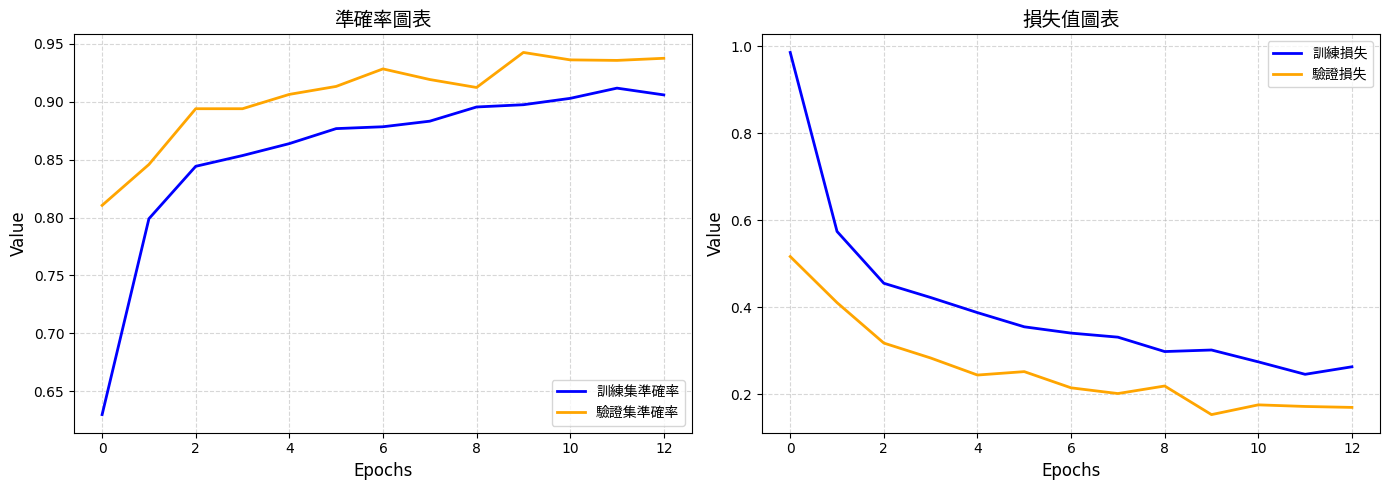

In [ ]:
!apt-get install -y fonts-noto-cjk > /dev/null
print("中文字體系統安裝成功")

font_path = '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc'
font_prop = fm.FontProperties(fname=font_path)

acc = history.history['accuracy']
val = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='訓練集準確率', color='blue', linewidth=2 )
plt.plot(epochs_range, val, label='驗證集準確率', color='orange', linewidth=2 )
plt.title('準確率圖表', fontproperties=font_prop, fontsize=14, fontweight='bold')
plt.legend(prop=font_prop, loc='lower right', fontsize=12)
plt.xlabel('Epochs',fontsize=12)
plt.ylabel('Value',fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='訓練損失', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='驗證損失', color='orange', linewidth=2)
plt.title('損失值圖表', fontproperties=font_prop, fontsize=14, fontweight='bold')
plt.legend(prop=font_prop, loc='upper right', fontsize=12)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# 實測模型

In [ ]:
!unzip -q tryfruits.zip -d /content/test_images

In [ ]:
all_paths = glob.glob('/content/test_images/**/*')
all_images=[]
for path in all_paths:
  if os.path.isfile(path):
    all_images.append(path)

for img_path in all_images:
  img_pil = tf.keras.utils.load_img(img_path,target_size=(150,150))
  img_3d = tf.keras.utils.img_to_array(img_pil)
  img_4d = tf.expand_dims(img_3d,axis=0)
  pred  = model.predict(img_4d,verbose=0)
  file_name = os.path.basename(img_path)
  pred_class = class_names[np.argmax(pred)]
  print(f'圖片:{file_name} 預測結果:{pred_class}')


圖片:fresh-a2.jpg 預測結果:freshapples
圖片:rotten-b2.jpg 預測結果:rottenapples
圖片:fresh-a1.jpg 預測結果:freshapples
圖片:fresh-b2.jpg 預測結果:freshbanana
圖片:rotten-o1.jpg 預測結果:rottenoranges
圖片:fresh-b1.jpg 預測結果:freshbanana
圖片:rotten-a1.jpg 預測結果:rottenapples
圖片:rotten-b1.jpg 預測結果:rottenbanana
圖片:fresh-o2.jpg 預測結果:freshoranges
圖片:rotten-o2.jpg 預測結果:freshoranges
圖片:fresh-o1.jpg 預測結果:freshoranges
圖片:rotten-a2.jpg 預測結果:rottenapples
